# Math 465 Fall 2026

## Module 2. Demo 1: Basic PCA on simulated and Wine data

Xiuyuan Cheng
xiuyuan.cheng@duke.edu

This notebook demonstrates:

- PCA on simple simulated data
- the equivalence between PCA and truncated SVD after centering
- PCA on the scikit-learn Wine data set
- interpretation of explained variance, scores, and loadings
- the effect of feature scaling

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D

from sklearn.decomposition import PCA

### Example 1. Dimension reduction from 3D to 2D

We used ``make_blobs`` in the k-means demo; here we use it again to produce simulated clustered data.

By default, the data are two-dimensional (this can be changed using the ``n_features`` argument). The number and centers of the clusters (three clusters by default), as well as the standard deviation of each Gaussian component (1.0 by default), can be changed by the user.

See the [documentation page](https://scikit-learn.org/stable/modules/generated/sklearn.datasets.make_blobs.html#sklearn.datasets.make_blobs).


In [2]:
from sklearn.datasets import make_blobs

In [3]:
random_state = 2026 # fix the random seed to obtain reproducible simulation results

random_state =  120

# generate the Gaussian mixture data in 3D
n_samples = 1000
X, y = make_blobs(n_samples=n_samples, 
                  n_features = 3,
                  random_state=random_state)

In [4]:
X.shape

(1000, 3)

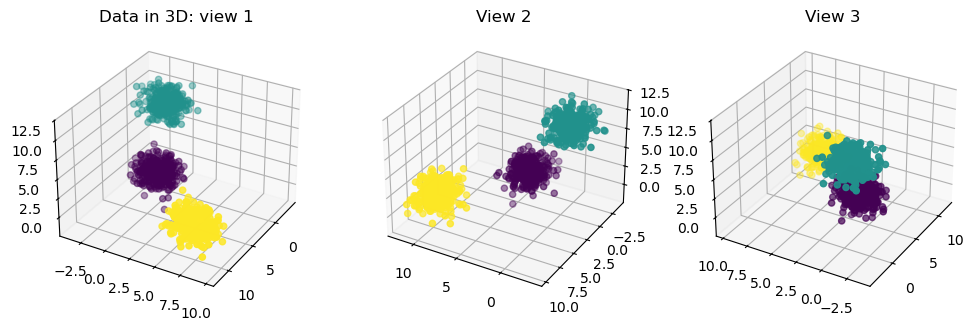

In [5]:

# plot the data colored by class labels
fig = plt.figure(figsize=(12, 4))
ax = fig.add_subplot(131, projection='3d')
ax.scatter(X[:, 0], X[:, 1], X[:,2], c=y)
ax.set_title("Data in 3D: view 1")
ax.view_init(30, 30)

ax = fig.add_subplot(132, projection='3d')
ax.scatter(X[:, 0], X[:, 1], X[:,2], c=y)
ax.set_title("View 2")
ax.view_init(30, 120)

ax = fig.add_subplot(133, projection='3d')
ax.scatter(X[:, 0], X[:, 1], X[:,2], c=y)
ax.set_title("View 3")
ax.view_init(30, 210)

plt.show()


In [6]:
# compute the PCA to reduce to 2D
output = PCA(n_components=2, svd_solver='full').fit(X)

In [7]:
output.components_

array([[ 0.69052069,  0.55421789, -0.46478351],
       [ 0.11364344,  0.55146719,  0.82641945]])

Text(0.5, 1.0, 'Projected data by PCA in 2D')

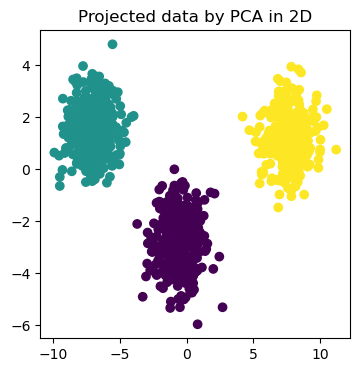

In [8]:
# the dimension-reduced representations of x_i
x2=output.fit_transform(X)


# plot the data colored by class labels
fig = plt.figure(figsize=(4, 4))
ax = fig.add_subplot(111)
ax.scatter(x2[:, 0], x2[:, 1], c=y)
ax.set_title("Projected data by PCA in 2D")

In [9]:
x2

array([[-6.23959769,  1.65053905],
       [ 7.62859822,  1.77105312],
       [ 2.08865257, -0.93921064],
       ...,
       [-6.79989789,  3.5616014 ],
       [-0.08919297, -3.25748725],
       [-5.96666111,  2.06127746]], shape=(1000, 2))

In [10]:
output.singular_values_

array([191.73692343,  69.57173106])

In [11]:
output.explained_variance_ratio_

array([0.86395463, 0.11374834])

In [12]:
sum(output.explained_variance_ratio_)

np.float64(0.9777029700194722)

We have shown in class that, mathematically, PCA is equivalent to the truncated SVD (after data vectors are centered).

Let's verify this using scikit-learn's ``TruncatedSVD`` function. See the [documentation page](https://scikit-learn.org/stable/modules/generated/sklearn.decomposition.TruncatedSVD.html#sklearn.decomposition.TruncatedSVD).


In [13]:
from sklearn.decomposition import TruncatedSVD

# we need to shift the data vectors to make mean zero
meanX = X.mean(axis=0)
meanX

array([4.27634864, 2.21876611, 4.50517987])

In [14]:
X_centered = X-meanX
X_centered.mean(axis=0)

array([-3.97637478e-15,  6.82565116e-16, -1.41309187e-15])

In [15]:
output_svd = TruncatedSVD(n_components=2, algorithm='arpack').fit(X_centered) 
output_svd.components_

array([[ 0.69052069,  0.55421789, -0.46478351],
       [ 0.11364344,  0.55146719,  0.82641945]])

In [16]:
output_svd.singular_values_

array([191.73692343,  69.57173106])

We can see that the PCs are indeed the singular vectors and that the singular values are the same as those returned by the PCA function above.

(Exercise) Verify that projecting onto the singular vectors gives the two-dimensional, dimension-reduced data representation.


Text(0.5, 1.0, 'Data in 2D using SVD')

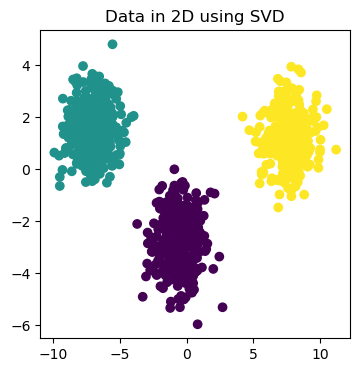

In [17]:
x3 = np.matmul( X_centered, np.transpose(output_svd.components_));

# plot the data colored by class labels
fig = plt.figure(figsize=(4, 4))
ax = fig.add_subplot(111)
ax.scatter(x3[:, 0], x3[:, 1], c=y)
ax.set_title("Data in 2D using SVD")

In [18]:
x3

array([[-6.23959769,  1.65053905],
       [ 7.62859822,  1.77105312],
       [ 2.08865257, -0.93921064],
       ...,
       [-6.79989789,  3.5616014 ],
       [-0.08919297, -3.25748725],
       [-5.96666111,  2.06127746]], shape=(1000, 2))

In [19]:
x2

array([[-6.23959769,  1.65053905],
       [ 7.62859822,  1.77105312],
       [ 2.08865257, -0.93921064],
       ...,
       [-6.79989789,  3.5616014 ],
       [-0.08919297, -3.25748725],
       [-5.96666111,  2.06127746]], shape=(1000, 2))

### Example 2. PCA of the Wine data set

The Wine data set contains 178 wines, 13 chemical measurements, and three cultivator classes. PCA is fitted without using the class labels. The labels are used only to color the score plots after dimension reduction.

In [20]:
from sklearn.datasets import load_wine
from sklearn.preprocessing import StandardScaler

In [21]:
wine = load_wine()
X_wine = wine.data
y_wine = wine.target
feature_names = np.array(wine.feature_names)

X_wine.shape, feature_names

((178, 13),
 array(['alcohol', 'malic_acid', 'ash', 'alcalinity_of_ash', 'magnesium',
        'total_phenols', 'flavanoids', 'nonflavanoid_phenols',
        'proanthocyanins', 'color_intensity', 'hue',
        'od280/od315_of_diluted_wines', 'proline'], dtype='<U28'))

The features are measured in different physical units. Before computing PCA, inspect their standard deviations. This determines whether covariance PCA will be dominated by variables with large numerical scales.

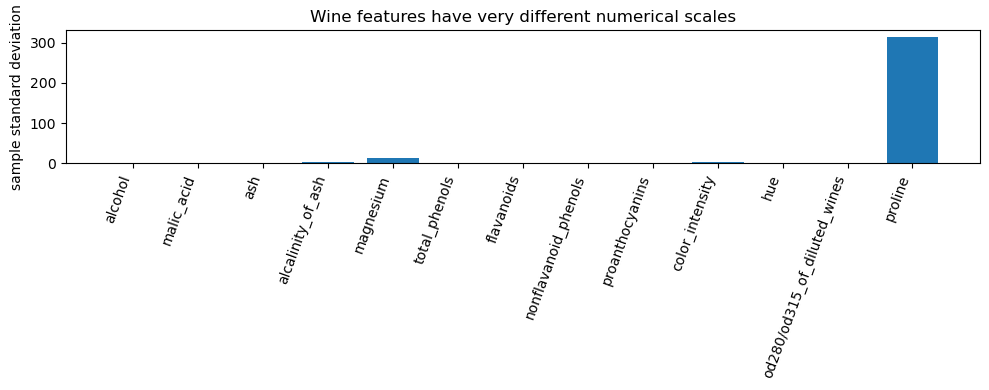

In [22]:
feature_std = X_wine.std(axis=0, ddof=1)

plt.figure(figsize=(10, 4))
plt.bar(np.arange(len(feature_names)), feature_std)
plt.xticks(np.arange(len(feature_names)), feature_names, rotation=70, ha='right')
plt.ylabel('sample standard deviation')
plt.title('Wine features have very different numerical scales')
plt.tight_layout()
plt.show()

#### PCA on centered, unstandardized measurements

The scikit-learn PCA function centers each feature automatically. It does not standardize feature variances.

In [23]:
pca_raw = PCA(n_components=2, svd_solver='full')
Z_raw = pca_raw.fit_transform(X_wine)

pca_raw.explained_variance_ratio_, pca_raw.explained_variance_ratio_.sum()

(array([0.99809123, 0.00173592]), np.float64(0.9998271461166032))

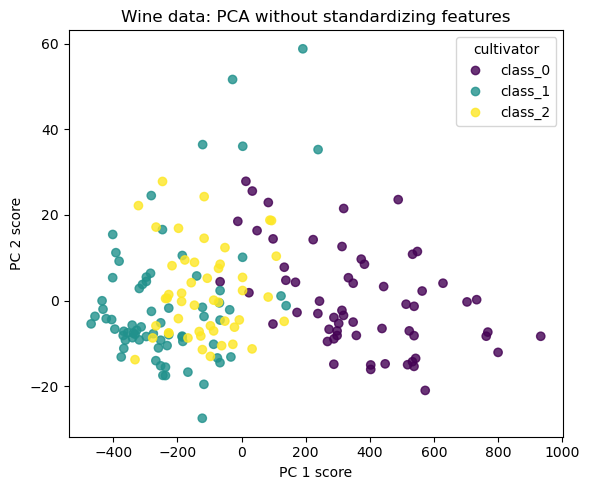

In [24]:
plt.figure(figsize=(6, 5))
scatter = plt.scatter(Z_raw[:, 0], Z_raw[:, 1], c=y_wine, cmap='viridis', alpha=0.8)
plt.xlabel('PC 1 score')
plt.ylabel('PC 2 score')
plt.title('Wine data: PCA without standardizing features')
plt.legend(scatter.legend_elements()[0], wine.target_names, title='cultivator')
plt.tight_layout()
plt.show()

In [25]:
raw_loading_order = np.argsort(np.abs(pca_raw.components_[0]))[::-1]
list(zip(feature_names[raw_loading_order[:5]], pca_raw.components_[0, raw_loading_order[:5]]))

[(np.str_('proline'), np.float64(0.9998229365233259)),
 (np.str_('magnesium'), np.float64(0.01786800750689538)),
 (np.str_('alcalinity_of_ash'), np.float64(-0.004671300581276232)),
 (np.str_('color_intensity'), np.float64(0.00232714319257675)),
 (np.str_('alcohol'), np.float64(0.001659264719642072))]

#### PCA after standardizing each feature

Standardization puts all 13 measurements on a common variance scale. Compare the score plot, explained variance, and loadings with the unstandardized analysis.

In [26]:
X_wine_std = StandardScaler().fit_transform(X_wine)
pca_std = PCA(n_components=2, svd_solver='full')
Z_std = pca_std.fit_transform(X_wine_std)

pca_std.explained_variance_ratio_, pca_std.explained_variance_ratio_.sum()

(array([0.36198848, 0.1920749 ]), np.float64(0.5540633835693527))

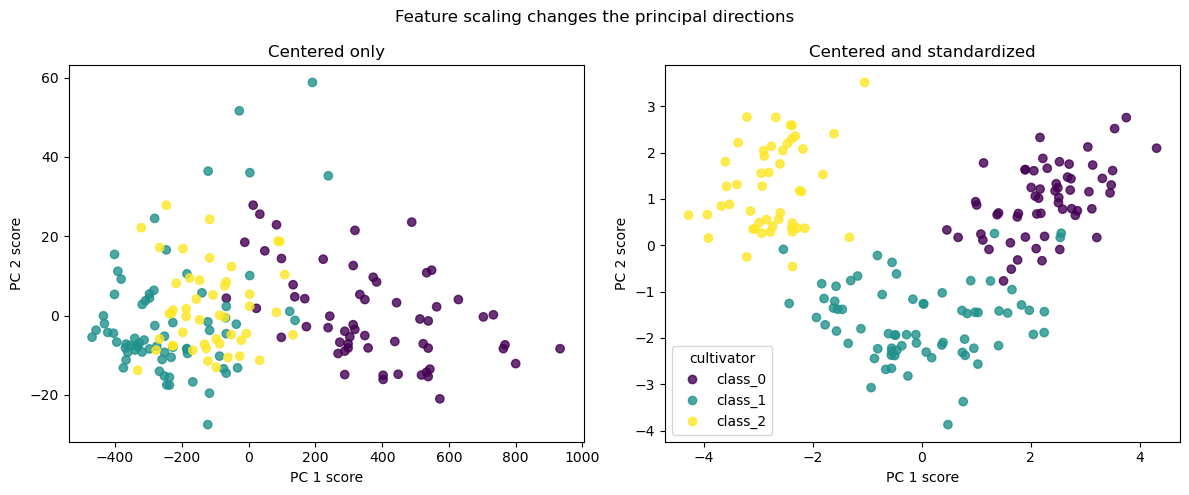

In [27]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

axes[0].scatter(Z_raw[:, 0], Z_raw[:, 1], c=y_wine, cmap='viridis', alpha=0.8)
axes[0].set_title('Centered only')
axes[0].set_xlabel('PC 1 score')
axes[0].set_ylabel('PC 2 score')

scatter = axes[1].scatter(Z_std[:, 0], Z_std[:, 1], c=y_wine, cmap='viridis', alpha=0.8)
axes[1].set_title('Centered and standardized')
axes[1].set_xlabel('PC 1 score')
axes[1].set_ylabel('PC 2 score')
axes[1].legend(scatter.legend_elements()[0], wine.target_names, title='cultivator')

fig.suptitle('Feature scaling changes the principal directions')
plt.tight_layout()
plt.show()

#### Interpretation questions

 Which variables dominate PCA before standardization, and why?
